# Stage 4. Postprocessing: Pareto front, priorities, weight map

**Question of the stage:** which strategy to choose under different priority settings of the regulator and how much this choice depends on weights and on the assessment of the damage of low-grade gasoline (c3). No new runs: the scenarios of stage 3 are used (`robust_scored.csv`, 9 finalists + 2 reference × 80 scenarios × 3 shocks) and, for context, the points of stage 2.

## Six profiles

As we discovered in stage 3, the best strategy mostly depends on two main things: the shock level and on the criterion of choice. The regulator may have different priorities: shortage, price, queues, or costs. We illustrate this with six profiles of weights for the four axes defined earlier in 02 during leveling. Here is the same table as in 02

| Axis | What it includes | Why |
|---|---|---|
| physical deficit | K0 | the main indicator of the crisis |
| price burden | K4, m.u. | K1 and K4 are both determined by price: in the screening their correlation across is 0.98–0.998. Two nearly identical axes add no information but increase the number of non-dominated points. K1 remains in the tables |
| queues | K5 above the no-shock background, h per car | the background (~2.7 h/car per year) exists even without a crisis; we compare what the shock and the measures add |
| cost of measures | K2 + c3 · K3, m.u., c3 = 0.25 | both quantities are the price of the measures for the budget and society. We reduce them to money via c3 (nominal 0.25 m.u./L — roughly the middle of the 0.05–0.5 range). Sensitivity to c3 is at stage 4, without runs |



Weights by axes (shortage / price / queues / costs), sum = 1:

| Profile | Weights |
|---|---|
| balanced | 0.25 / 0.25 / 0.25 / 0.25 |
| shortage_first (deficit above all) | 0.55 / 0.15 / 0.15 / 0.15 |
| price_first (consumer price) | 0.15 / 0.55 / 0.15 / 0.15 |
| budget_first (budget) | 0.15 / 0.15 / 0.15 / 0.55 |
| queues_first (social stability) | 0.15 / 0.15 / 0.55 / 0.15 |
| physical_security (deficit + queues) | 0.40 / 0.10 / 0.40 / 0.10 |

The main priority weighs 0.55, not 1.0: with a weight of 1 and zero for the others, a strategy that is catastrophic on other axes would win. With 0.55, the main priority weighs more than the other three combined (0.55 > 0.45), but they continue to constrain the choice. 



## How to calculate the score

The same as with stage 3: in each scenario (uncertainty point × shock × seed) each axis is normalized min–max over 11 strategies (0 = best and 1 = worst), the score = weighted sum of the normalized axes. The choice is based on the **90th percentile** of the score over 80 shock scenarios (a strategy that performs poorly in 10% of the worst scenarios is penalized); for comparison - by average. A robust choice for all shocks is the one with the lowest worst-case 90th percentile across three shocks. Only the finalists S1–S9 can be chosen; reference strategies participate in the normalization.

## 4.0. Environment

In [1]:
import json, itertools, math, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
import batch_runner as br

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
GRAY = "#b9b7b0"
SCOL = {"S1": "#2a78d6", "S2": "#eb6834", "S3": "#1baf7a", "S4": "#eda100", "S5": "#8a5cd1",
        "S6": "#e0457b", "S7": "#13a3b8", "S8": "#7a8a1f", "S9": "#9c6b3c", "none": "#52514e", "L2_only": GRAY}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110, "axes.prop_cycle": plt.cycler(color=PAL)})

OUT_DIR = Path("results")
PREP = json.loads((OUT_DIR / "prep_summary.json").read_text(encoding="utf-8"))
RBS  = json.loads((OUT_DIR / "robust_summary.json").read_text(encoding="utf-8"))
RS   = br.read_results(OUT_DIR / "robust_scored.csv")  
LV   = br.read_results(OUT_DIR / "levels_scored.csv")  

SHOCKS  = PREP["shock_levels"]
STRATS  = RBS["strategies"]
NAMES   = list(STRATS)
FIN     = [s for s in NAMES if s not in ("none", "L2_only")]
AXES    = ["K0", "K4", "K5_excess", "COST"]
AX_LAB  = {"K0": "shortage K0", "K4": "price burden K4", "K5_excess": "queues K5 above background", "COST": "policy cost K2 + c3*K3"}
SUB0    = PREP["interface_defaults"]["L4-subsidy"]
C3_NOM  = RBS["c3_nominal"]
C3_RANGE = PREP["c3_range"]
KEY     = ["u_id", "shock", "seed"]
PROFILES = {
    "balanced":          {"K0": 0.25, "K4": 0.25, "K5_excess": 0.25, "COST": 0.25},
    "shortage_first":    {"K0": 0.55, "K4": 0.15, "K5_excess": 0.15, "COST": 0.15},
    "price_first":       {"K0": 0.15, "K4": 0.55, "K5_excess": 0.15, "COST": 0.15},
    "budget_first":      {"K0": 0.15, "K4": 0.15, "K5_excess": 0.15, "COST": 0.55},
    "queues_first":      {"K0": 0.15, "K4": 0.15, "K5_excess": 0.55, "COST": 0.15},
    "physical_security": {"K0": 0.40, "K4": 0.10, "K5_excess": 0.40, "COST": 0.10},
}


In [2]:
none = RS.loc[RS.strategy == "none", KEY + ["K1", "K0@90"]].rename(columns={"K1": "K1_none", "K0@90": "K090_none"})
RS = RS.drop(columns=[c for c in ["K1_none", "K090_none"] if c in RS]).merge(none, on=KEY, how="left")
RS["K1_rel"] = RS.K1 / RS.K1_none
RS["K0_90_rel"] = RS["K0@90"] / RS.K090_none.clip(lower=1)
n_scen = RS.groupby(KEY).ngroups
print(f"stage-3 scenarios: {n_scen} ({n_scen // len(SHOCKS)} per shock), strategies: {len(NAMES)}")
pd.DataFrame([{"strategy": s, "point_id": v["point_id"], "role": v["role"]} for s, v in STRATS.items()])

stage-3 scenarios: 240 (80 per shock), strategies: 11


,strategy,point_id,role
0,S1,A31,best worst-case score across shocks
1,S2,A15,best at shock 0.2
2,S3,A53,best at shock 0.45
3,S4,A41,best at shock 0.7
4,S5,A09,closest to ideal at shock 0.45
5,S6,A23,closest to ideal at shock 0.7
6,S7,A30,minimum shortage (max supply)
7,S8,A59,"minimum overpayment, expensive"
8,S9,B36,best without price cap
9,none,none,reference


## 4.1. Pareto front of the finalists

A strategy is **Pareto-efficient** if no other strategy is better or equal to it on all four axes and strictly better on at least one. 


Here we calculate it in two ways:
* by **averages** over 80 shock scenarios - the "typical" front;
* by the **90th percentile** - the front for a cautious regulator (each axis is its value in the worst 10% of scenarios);
* and the **proportion of scenarios**, in which the strategy is Pareto-efficient among 11 - how often it is a reasonable choice in general.


In [3]:
def nondominated(F):
    F = np.asarray(F, float)
    return np.array([not (np.all(F <= F[i], axis=1) & np.any(F < F[i], axis=1)).any() for i in range(len(F))])

REL = {"K0": "K0_rel", "K4": "K4_rel", "K5_excess": "K5_excess", "COST": "COST"}
rows = []
for sh in SHOCKS:
    d = RS[RS.shock == sh]
    mean = d.groupby("strategy")[list(REL.values()) + ["K1_rel", "K0_90_rel"]].mean().reindex(NAMES)
    p90 = d.groupby("strategy")[list(REL.values())].quantile(0.9).reindex(NAMES)
    nd_mean = nondominated(mean[list(REL.values())])
    nd_p90 = nondominated(p90)
    nd_rows = [pd.Series(nondominated(g[AXES]), index=g.strategy.to_numpy()) for _, g in d.groupby(KEY)]
    share = pd.concat(nd_rows, axis=1).mean(axis=1).reindex(NAMES)
    for s in NAMES:
        rows.append({"shock": sh, "strategy": s, **{f"{k}_mean": mean.loc[s, k] for k in mean.columns},
                     **{f"{REL[a]}_p90": p90.loc[s, REL[a]] for a in AXES},
                     "nd_mean": nd_mean[NAMES.index(s)], "nd_p90": nd_p90[NAMES.index(s)], "nd_scenario_share": share.loc[s]})
PARETO = pd.DataFrame(rows)
PARETO.to_csv(OUT_DIR / "stage4_pareto.csv", index=False, encoding="utf-8-sig")
for sh in SHOCKS:
    print(f"\n=== shock-depth = {sh} ===")
    display(PARETO[PARETO.shock == sh].drop(columns="shock").set_index("strategy").round(3))


=== shock-depth = 0.2 ===


,K0_rel_mean,K4_rel_mean,K5_excess_mean,COST_mean,K1_rel_mean,K0_90_rel_mean,K0_rel_p90,K4_rel_p90,K5_excess_p90,COST_p90,nd_mean,nd_p90,nd_scenario_share
strategy,,,,,,,,,,,,,
S1,0.027,0.174,0.667,64678.096,0.214,0.010,0.076,0.286,0.485,79537.722,True,True,0.962
S2,0.029,0.088,0.676,94750.991,0.110,0.020,0.039,0.156,0.637,109022.414,True,True,1.000
S3,0.012,0.174,0.858,62473.899,0.214,0.018,0.032,0.283,1.604,76887.649,True,True,0.900
S4,0.015,0.103,0.752,150182.327,0.129,0.009,0.001,0.173,0.588,160075.200,True,True,0.912
S5,0.029,0.190,1.569,108199.929,0.231,0.021,0.084,0.335,3.742,112055.116,False,False,0.438
S6,0.026,0.163,0.821,91089.232,0.202,0.032,0.002,0.289,0.541,104567.502,True,True,0.812
S7,0.022,0.002,0.907,363132.278,0.003,0.015,0.000,0.004,1.267,375625.659,True,True,1.000
S8,0.018,0.144,0.262,92600.145,0.179,0.005,0.000,0.243,0.507,107557.182,True,True,0.938
S9,0.011,0.166,0.990,91748.450,0.205,0.004,0.002,0.288,1.224,106418.177,True,True,0.788



=== shock-depth = 0.45 ===


,K0_rel_mean,K4_rel_mean,K5_excess_mean,COST_mean,K1_rel_mean,K0_90_rel_mean,K0_rel_p90,K4_rel_p90,K5_excess_p90,COST_p90,nd_mean,nd_p90,nd_scenario_share
strategy,,,,,,,,,,,,,
S1,0.089,0.142,1.970,168324.195,0.209,0.128,0.198,0.232,4.937,185488.304,True,True,0.975
S2,0.190,0.043,4.618,183183.746,0.067,0.281,0.429,0.074,13.490,195571.492,True,True,1.000
S3,0.323,0.124,19.255,122958.500,0.184,0.326,0.979,0.213,56.490,126106.376,True,True,1.000
S4,0.093,0.240,3.270,198603.095,0.334,0.104,0.271,0.377,10.464,207139.606,False,False,0.388
S5,0.265,0.199,21.964,107486.392,0.285,0.210,0.884,0.347,68.063,110364.773,True,True,1.000
S6,0.089,0.222,4.014,142679.231,0.314,0.117,0.229,0.331,13.171,148916.527,True,True,0.975
S7,0.025,0.122,2.747,412095.993,0.182,0.032,0.057,0.194,7.044,422061.678,True,True,0.962
S8,0.069,0.082,2.195,202863.658,0.125,0.101,0.154,0.142,5.447,222455.907,True,True,1.000
S9,0.064,0.237,3.571,161086.384,0.328,0.083,0.181,0.351,11.759,172314.876,True,True,0.962



=== shock-depth = 0.7 ===


,K0_rel_mean,K4_rel_mean,K5_excess_mean,COST_mean,K1_rel_mean,K0_90_rel_mean,K0_rel_p90,K4_rel_p90,K5_excess_p90,COST_p90,nd_mean,nd_p90,nd_scenario_share
strategy,,,,,,,,,,,,,
S1,0.159,0.120,6.279,254671.789,0.202,0.246,0.297,0.186,17.178,268929.650,True,True,1.000
S2,1.427,0.028,91.270,195563.017,0.052,0.821,2.789,0.046,168.576,197152.010,True,True,1.000
S3,2.693,0.079,150.563,126375.000,0.144,0.967,5.002,0.131,228.730,126750.000,True,True,1.000
S4,0.144,0.257,12.490,192787.529,0.390,0.208,0.310,0.380,30.143,198742.070,True,True,0.950
S5,2.487,0.130,152.954,100723.360,0.227,0.807,4.357,0.215,237.660,103246.170,True,True,1.000
S6,0.385,0.240,54.897,143977.714,0.376,0.337,0.886,0.329,155.458,146522.357,True,True,1.000
S7,0.033,0.152,6.746,418929.992,0.249,0.051,0.087,0.236,17.830,431451.209,True,True,0.975
S8,0.142,0.055,7.044,304907.640,0.098,0.219,0.288,0.088,16.057,324279.926,True,True,1.000
S9,0.102,0.355,9.964,165474.022,0.480,0.156,0.226,0.507,24.691,171453.574,True,True,1.000


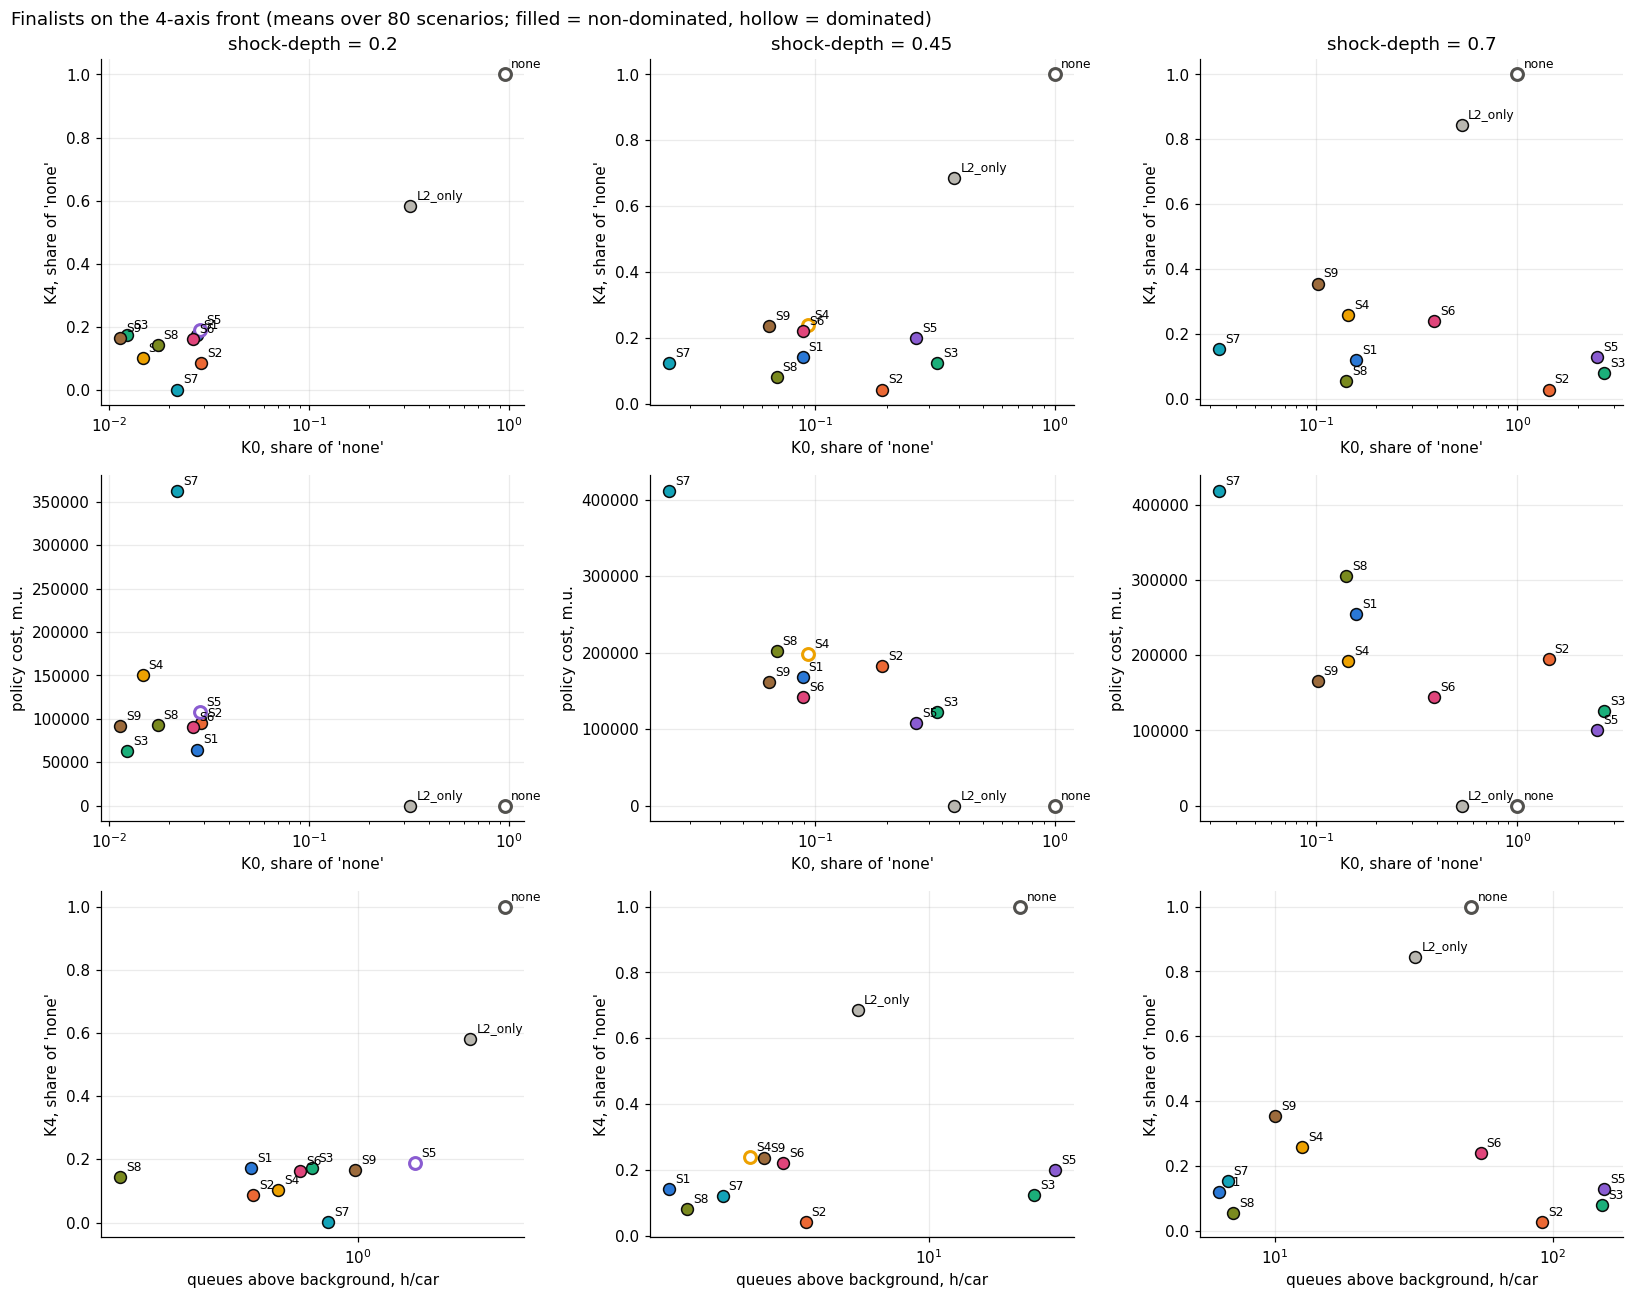

In [4]:
proj = [("K0_rel", "K4_rel"), ("K0_rel", "COST"), ("K5_excess", "K4_rel")]
lab = {"K0_rel": "K0, share of 'none'", "K4_rel": "K4, share of 'none'",
       "K5_excess": "queues above background, h/car", "COST": "policy cost, m.u."}
fig, axes = plt.subplots(len(proj), 3, figsize=(15, 12))
for j, sh in enumerate(SHOCKS):
    p = PARETO[PARETO.shock == sh]
    for i, (x, y) in enumerate(proj):
        ax = axes[i, j]
        for r in p.itertuples():
            xv, yv = getattr(r, x + "_mean"), getattr(r, y + "_mean")
            if x == "K0_rel":
                xv = max(xv, 1e-3)
            if r.nd_mean:
                ax.scatter(xv, yv, s=60, color=SCOL[r.strategy], edgecolor="#0b0b0b", linewidth=1.0, zorder=3)
            else:
                ax.scatter(xv, yv, s=60, facecolor="white", edgecolor=SCOL[r.strategy], linewidth=2.0, zorder=3)
            ax.annotate(r.strategy, (xv, yv), fontsize=8, xytext=(4, 4), textcoords="offset points")
        if x == "K0_rel":
            ax.set_xscale("log")
        if x == "K5_excess":
            ax.set_xscale("symlog", linthresh=1)
        ax.set_xlabel(lab[x]); ax.set_ylabel(lab[y])
        if i == 0: ax.set_title(f"shock-depth = {sh}")
fig.suptitle("Finalists on the 4-axis front (means over 80 scenarios; filled = non-dominated, hollow = dominated)",
             x=0.01, ha="left")
plt.tight_layout(); plt.show()

The dots that are fully filled are Pareto-efficient, the empty ones are dominated by at least one other strategy.


The figure shows the nine finalists and two references on three projections of the four-axis front. Almost all finalists are non-dominated, so the front alone does not select a strategy, but it removes three: S5 is being dominated at shock 0.2 and S4 at shock 0.45, and the export ban alone dominates "no measures" at every shock. 

At shock 0.7 the front offers a wide range of options: lowest shortage at the highest cost (S7), low overpayment and queues with moderate shortage (S1), lowest overpayment near the cost limit (S8), or cheaper low-shortage options with two to three times higher overpayment (S9, S4). 

### Stage 2 front and finalists

All 102 points of stage 2 at nominal parameters: gray - dominated, blue - non-dominated on four axes, finalists are labeled. Shows where the finalists came from and what the trade-off "deficit ↔ overpayment" looks like.



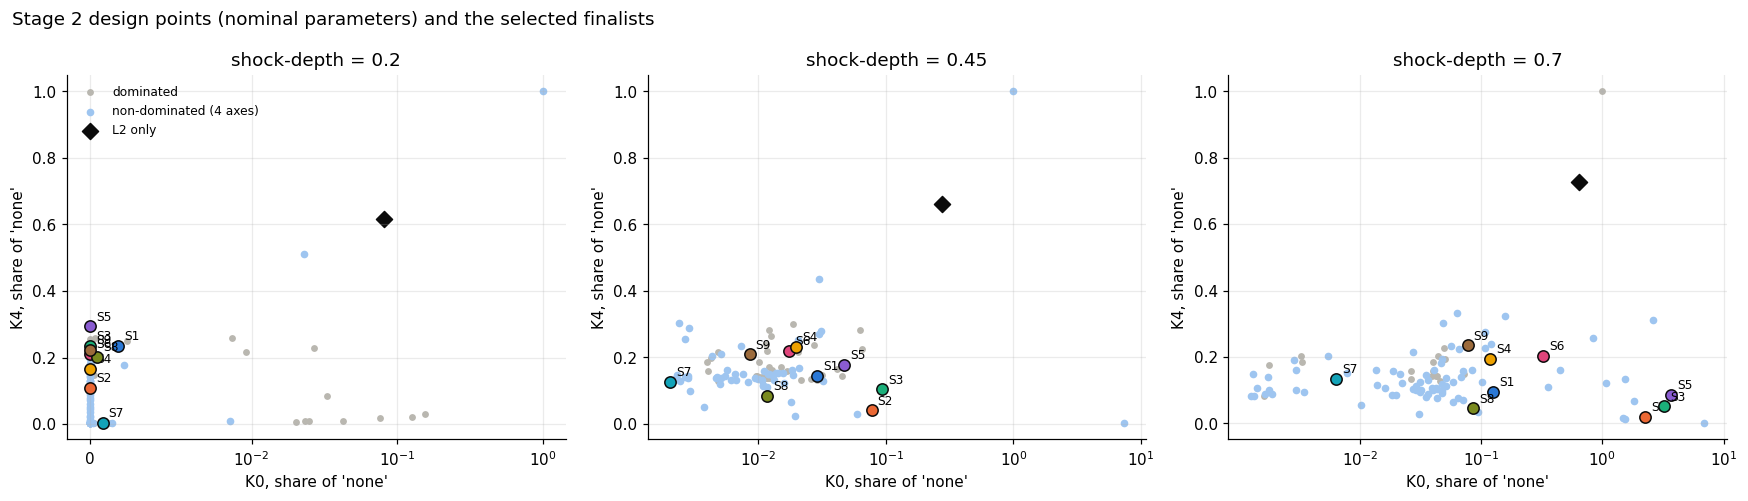

In [5]:
pid2s = {v["point_id"]: s for s, v in STRATS.items() if s in FIN}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, sh in zip(axes, SHOCKS):
    d = LV[LV.shock == sh]
    ax.scatter(d[~d.nd].K0_rel, d[~d.nd].K4_rel, s=12, color=GRAY, label="dominated")
    ax.scatter(d[d.nd].K0_rel, d[d.nd].K4_rel, s=16, color="#9ec5f0", label="non-dominated (4 axes)")
    for r in d[d.point_id.isin(pid2s)].itertuples():
        s = pid2s[r.point_id]
        ax.scatter(r.K0_rel, r.K4_rel, s=55, color=SCOL[s], edgecolor="#0b0b0b", zorder=3)
        ax.annotate(s, (r.K0_rel, r.K4_rel), fontsize=8, xytext=(4, 4), textcoords="offset points")
    a = d[d.point_id == "L2_only"]
    ax.scatter(a.K0_rel, a.K4_rel, s=55, marker="D", color="#0b0b0b", label="L2 only")
    ax.set_xscale("symlog", linthresh=0.01); ax.set_xlabel("K0, share of 'none'"); ax.set_ylabel("K4, share of 'none'")
    ax.set_title(f"shock-depth = {sh}")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Stage 2 design points (nominal parameters) and the selected finalists", x=0.01, ha="left")
plt.tight_layout(); plt.show()

## 4.2. Scoring

Here we calculate the score for each strategy under six profiles of weights and three shocks. The score is the weighted sum of the normalized axes, and we consider both the average and the 90th percentile over 80 shock scenarios. The strategy with the lowest score is considered the best choice for that profile and shock level.


- Subsidy: the size of the subsidy used for imports (0.25 as default)
- c3: this is how we evaluate the cost of low-grade gasoline (0.25 as default)  

Earlier during the runs we used fixed values of subsidy and c3, as they do not influence our model runs - subsidy makes no change over import volumes, and c3 does not even exist in the current model at all. However, we now can explore how sensitive the choice of strategy is to these parameters. 

In [6]:
def build_norm(c3=C3_NOM, subsidy=SUB0):
    """This function builds normalized data for each shock scenario based on the given c3 and subsidy values.
    
    Parameters:
        c3 (float): The value of c3 to be used in the cost calculation.
        subsidy (float): The subsidy value to be used in the cost calculation.
    
    Returns:
        dict: A dictionary containing the normalized data for each shock scenario.
    
    """
    
    
    d = RS[KEY + ["strategy", "K0", "K4", "K5_excess", "K2", "K3_volume"]].copy()
    d["COST"] = d.K2 * subsidy / SUB0 + c3 * d.K3_volume
    out = {}
    for sh in SHOCKS:
        ds = d[d.shock == sh]
        arrs = []
        for a in AXES:
            m = ds.pivot_table(index=["u_id", "seed"], columns="strategy", values=a)[
                NAMES].to_numpy(float)
            lo, hi = m.min(axis=1, keepdims=True), m.max(axis=1, keepdims=True)
            arrs.append(np.where(hi > lo, (m - lo) /
                        np.where(hi > lo, hi - lo, 1), 0.0))
        out[sh] = np.stack(arrs, axis=2)
    return out


def evaluate(weights, norm):
    """This function evaluates the strategies using the given weights and normalized data.

    Parameters:
        weights (dict): A dictionary containing the weights for each axis.
        norm (dict): A dictionary containing the normalized data for each shock.

    Returns:
        dict: A dictionary containing the evaluation results for each shock, with P90 and mean values

    """
    w = np.array([weights[a] for a in AXES], float)
    res = {}
    for sh, N in norm.items():
        S = N @ w  # multiply normalized values by weights vector to get weighted sum for each scenario and strategy
        res[sh] = pd.DataFrame(
            {"p90": np.quantile(S, 0.9, axis=0), "mean": S.mean(axis=0)}, index=NAMES)
    return res


def choose(res, by="p90"):
    """This function selects the best and worst strategies based on the evaluation results.
    
    Parameters:
        res (dict): A dictionary containing the evaluation results for each shock.
        by (str): The metric to use for selecting the best and worst strategies. Default is "p90".
        
    Returns:
        tuple: A tuple containing the best strategy for each shock, the overall worst strategy, and the worst values.
    
    """
    
    best = {sh: r.loc[FIN, by].idxmin() for sh, r in res.items()}
    worst = pd.concat({sh: r.loc[FIN, by]
                      for sh, r in res.items()}, axis=1).max(axis=1)
    return best, worst.idxmin(), worst


NORM0 = build_norm()
res_eq = evaluate(PROFILES["balanced"], NORM0)
st3 = br.read_results(
    OUT_DIR / "robust_summary_table.csv").set_index(["shock", "strategy"]).score_p90
diff = max(abs(res_eq[sh].loc[s, "p90"] - st3.loc[(sh, s)])
           for sh in SHOCKS for s in NAMES)
print(
    f"check vs stage 3 (equal weights, nominal c3 and subsidy): max |P90 difference| = {diff:.2e}")

check vs stage 3 (equal weights, nominal c3 and subsidy): max |P90 difference| = 1.11e-16


New mechanism for calculation in section 4.2 correctly reproduces the P90 of stage 3 with the original parameters. The normalization formula and the calculation of weighted scores are consistent with the previous implementation in the tested baseline mode.

## 4.3. Priority - Strategy Table

For every profile: the best strategy for each shock (based on the 90th percentile and the mean) and one stable strategy across all shocks. `margin` - how much worse is the second-best strategy compared to the first based on the 90th percentile (a small margin = a nearly equal choice, so it's worth looking at the second one as well).

In [7]:
rows = []
for pname, w in PROFILES.items():
    res = evaluate(w, NORM0)
    best_p, rob_p, worst_p = choose(res, "p90")
    best_m, rob_m, _ = choose(res, "mean")
    r = {"profile": pname}
    for sh in SHOCKS:
        v = res[sh].loc[FIN, "p90"].sort_values()
        r[f"best@{sh}"] = best_p[sh]
        r[f"margin@{sh}"] = v.iloc[1] - v.iloc[0]
        r[f"best_by_mean@{sh}"] = best_m[sh]
    ws = worst_p.sort_values()
    r.update({"robust_all_shocks": rob_p, "robust_worst_p90": ws.iloc[0], "robust_runner_up": ws.index[1],
              "robust_margin": ws.iloc[1] - ws.iloc[0], "robust_by_mean": rob_m})
    rows.append(r)
PRIO = pd.DataFrame(rows).set_index("profile")
PRIO.to_csv(OUT_DIR / "stage4_priority_table.csv", encoding="utf-8-sig")
print("Priority profile -> recommended strategy (selection by P90 of the weighted score):")
display(PRIO[[f"best@{sh}" for sh in SHOCKS] + ["robust_all_shocks", "robust_runner_up", "robust_margin"]])
print("Margins and selection by mean (for comparison):")
display(PRIO[[f"margin@{sh}" for sh in SHOCKS] + [f"best_by_mean@{sh}" for sh in SHOCKS] + ["robust_by_mean"]].round(3))

Priority profile -> recommended strategy (selection by P90 of the weighted score):


,best@0.2,best@0.45,best@0.7,robust_all_shocks,robust_runner_up,robust_margin
profile,,,,,,
balanced,S1,S1,S1,S1,S8,0.034261
shortage_first,S8,S1,S1,S1,S8,0.005844
price_first,S2,S8,S8,S8,S1,0.007741
budget_first,S1,S1,S9,S9,S1,0.068734
queues_first,S8,S1,S1,S1,S9,0.077979
physical_security,S8,S1,S1,S1,S9,0.057638


Margins and selection by mean (for comparison):


,margin@0.2,margin@0.45,margin@0.7,best_by_mean@0.2,best_by_mean@0.45,best_by_mean@0.7,robust_by_mean
profile,,,,,,,
balanced,0.008,0.034,0.013,S1,S1,S1,S1
shortage_first,0.001,0.006,0.005,S3,S1,S9,S1
price_first,0.018,0.023,0.037,S2,S8,S8,S8
budget_first,0.000,0.002,0.029,S3,S6,S9,S9
queues_first,0.008,0.078,0.012,S1,S1,S1,S1
physical_security,0.018,0.058,0.007,S1,S1,S1,S1


As we found in stage 3, S1 is the best choice for the balanced profile. It also leads in security, budgeting, shortage optimization - the higher the shock level, the more S1 is preferred. S1 is followed by S2, S8 and S9, but they are still nowhere as near as S1 in terms of how often it is recommended to be used 

Then we display our advices to the regulator in a table, that shows the best strategy and how to implement it for each profile and shock level

In [8]:
def levers(s):
    """
    This function retrieves the policy levers for a given strategy.
    
    Parameters:
        s (str): The strategy identifier.
    
    Returns:
        dict: A dictionary containing the policy levers for the specified strategy.
    """
    
    
    p = STRATS[s]["params"]
    return {"L3": p["L3-share-naphtha"] if p["L3-quality-relax?"] else 0.0,
            "L4": p["L4-import-limit"] if p["L4-import?"] else 0.0,
            "L5_L": p["L5-liters-per-fillup"] if p["L5-fillup-limit?"] else "off",
            "L6_cap": p["L6-price-cap"] if p["L6-price-cap?"] else "off"}

rows = []
for pname in PROFILES:
    for sh in SHOCKS:
        s = PRIO.loc[pname, f"best@{sh}"]
        m = PARETO[(PARETO.shock == sh) & (PARETO.strategy == s)].iloc[0]
        rows.append({"profile": pname, "shock": sh, "strategy": s, **levers(s),
                     "K0_rel": m.K0_rel_mean, "K4_rel": m.K4_rel_mean, "K5_h_per_car": m.K5_excess_mean,
                     "COST": m.COST_mean, "K1_rel": m.K1_rel_mean, "K0_day90_rel": m.K0_90_rel_mean})
RECO = pd.DataFrame(rows)
RECO.to_csv(OUT_DIR / "stage4_recommendations.csv", index=False, encoding="utf-8-sig")
RECO.round(3)

,profile,shock,strategy,L3,L4,L5_L,L6_cap,K0_rel,K4_rel,K5_h_per_car,COST,K1_rel,K0_day90_rel
0,balanced,0.20,S1,0.00,0.22,70.0,1.35,0.027,0.174,0.667,64678.096,0.214,0.010
1,balanced,0.45,S1,0.00,0.22,70.0,1.35,0.089,0.142,1.970,168324.195,0.209,0.128
2,balanced,0.70,S1,0.00,0.22,70.0,1.35,0.159,0.120,6.279,254671.789,0.202,0.246
3,shortage_first,0.20,S8,0.05,0.26,50.0,1.1,0.018,0.144,0.262,92600.145,0.179,0.005
4,shortage_first,0.45,S1,0.00,0.22,70.0,1.35,0.089,0.142,1.970,168324.195,0.209,0.128
5,shortage_first,0.70,S1,0.00,0.22,70.0,1.35,0.159,0.120,6.279,254671.789,0.202,0.246
6,price_first,0.20,S2,0.05,0.13,65.0,1.05,0.029,0.088,0.676,94750.991,0.110,0.020
7,price_first,0.45,S8,0.05,0.26,50.0,1.1,0.069,0.082,2.195,202863.658,0.125,0.101
8,price_first,0.70,S8,0.05,0.26,50.0,1.1,0.142,0.055,7.044,304907.640,0.098,0.219
9,budget_first,0.20,S1,0.00,0.22,70.0,1.35,0.027,0.174,0.667,64678.096,0.214,0.010


## 4.4. Weight map



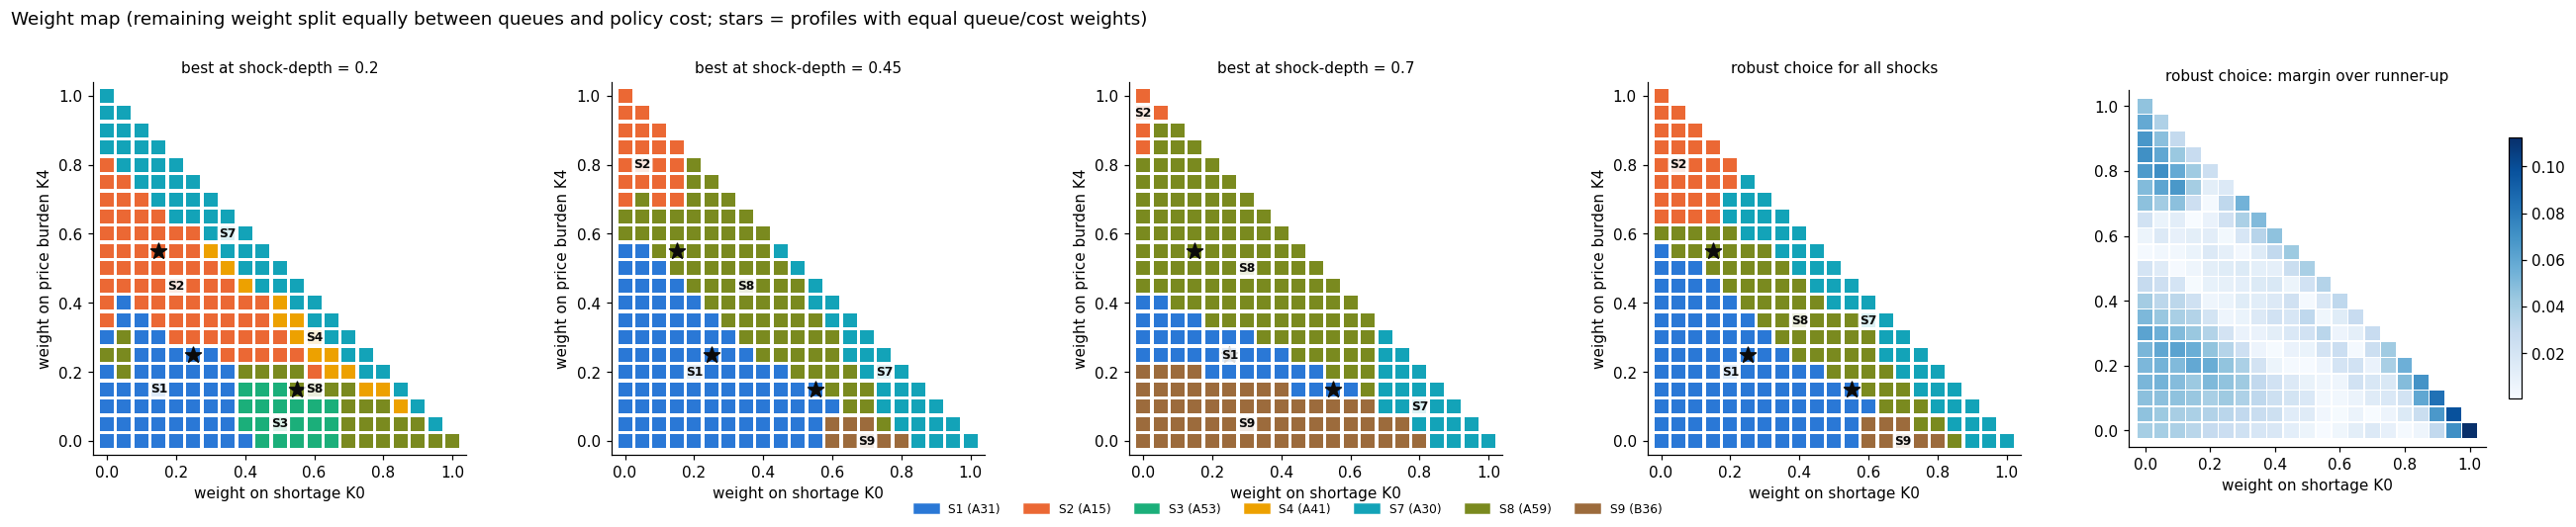

In [9]:
STEP = 0.05
grid = [(round(a, 2), round(b, 2)) for a in np.arange(0, 1 + 1e-9, STEP) for b in np.arange(0, 1 - a + 1e-9, STEP)]

def weight_map(norm):
    rows = []
    for a, b in grid:
        rest = (1 - a - b) / 2
        res = evaluate({"K0": a, "K4": b, "K5_excess": rest, "COST": rest}, norm)
        best, rob, worst = choose(res, "p90")
        ws = worst.sort_values()
        rows.append({"w_K0": a, "w_K4": b, **{f"best@{sh}": best[sh] for sh in SHOCKS},
                     "robust": rob, "robust_margin": ws.iloc[1] - ws.iloc[0]})
    return pd.DataFrame(rows)

WMAP = weight_map(NORM0)
WMAP.to_csv(OUT_DIR / "stage4_weight_map.csv", index=False, encoding="utf-8-sig")

prof_xy = {p: (w["K0"], w["K4"]) for p, w in PROFILES.items() if abs(w["K5_excess"] - w["COST"]) < 1e-9}
cols = [f"best@{sh}" for sh in SHOCKS] + ["robust"]
titles = [f"best at shock-depth = {sh}" for sh in SHOCKS] + ["robust choice for all shocks"]
fig, axes = plt.subplots(1, 5, figsize=(24, 4.8))
for ax, c, t in zip(axes[:4], cols, titles):
    for s in FIN:
        d = WMAP[WMAP[c] == s]
        ax.scatter(d.w_K0, d.w_K4, s=95, marker="s", color=SCOL[s], linewidth=0)
        if len(d) >= 3:
            
            cx, cy = d.w_K0.mean(), d.w_K4.mean()
            k = ((d.w_K0 - cx) ** 2 + (d.w_K4 - cy) ** 2).idxmin()
            ax.annotate(s, (d.loc[k, "w_K0"], d.loc[k, "w_K4"]), fontsize=8, ha="center", va="center", color="#0b0b0b",
                        fontweight="bold", bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": 0.85})
    for p, (x, y) in prof_xy.items():
        ax.scatter(x, y, marker="*", s=120, color="#0b0b0b")
    ax.set_xlim(-0.04, 1.04); ax.set_ylim(-0.04, 1.04); ax.set_aspect("equal"); ax.grid(False)
    ax.set_xlabel("weight on shortage K0"); ax.set_ylabel("weight on price burden K4"); ax.set_title(t, fontsize=10)
sc = axes[4].scatter(WMAP.w_K0, WMAP.w_K4, c=WMAP.robust_margin, cmap="Blues", s=95, marker="s", linewidth=0)
axes[4].set_aspect("equal"); axes[4].grid(False); axes[4].set_title("robust choice: margin over runner-up", fontsize=10)
axes[4].set_xlabel("weight on shortage K0"); fig.colorbar(sc, ax=axes[4], shrink=0.7)
handles = [Patch(color=SCOL[s], label=f"{s} ({STRATS[s]['point_id']})") for s in FIN if (WMAP[cols] == s).any().any()]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, fontsize=8)
fig.suptitle("Weight map (remaining weight split equally between queues and policy cost; stars = profiles with equal "
             "queue/cost weights)", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0.06, 1, 0.94)); plt.show()


Stars are the priority profiles marked on the weight map. Each one is placed at a point corresponding to the profile's weights, so you can see which region it falls into. On the map only profiles with equal queue and cost weights are shown, that way only shortage and price burdens vary on two dimensional map. 

The weight map clear shows the policy choice as the ladder at medium and severe shocks. With balanced priorities S1 is the best choice, again, As the weight on consumer prices increases, tighter caps backed by more imports become optimal (S8 with cap 1.1, then S2 with cap 1.05). As the weight on shortage increases, maximum supply (S7) wins; when prices carry little weight, no cap (S9) is preferred at the severe shock. Four finalists (S3–S6) are never the robust choice.

Margin over runner-up shows how much worse the second-best strategy is compared to the best one. The lighter the color, the smaller the margin, and the more equal the choice

In [10]:

print("Share of the weight simplex where each strategy is the robust choice:")
display(WMAP.robust.value_counts(normalize=True).rename("share").to_frame().round(3))

Share of the weight simplex where each strategy is the robust choice:


,share
robust,
S1,0.403
S8,0.242
S7,0.199
S2,0.121
S9,0.035


## 4.5. Sensitivity to c3 and import subsidy

As mentioned earlier in this notebook, c3 (damage from a liter of low-grade gasoline) and import subsidy do not affect the course of the simulation, so they can be changed without running new simulations. Des the recommendation change if low-grade gasoline causes greater or lesser damage, or if imports are more expensive?

Robust choice by profile (rows) and c3 (columns), nominal subsidy:


c3,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50
profile,,,,,,,,,,
balanced,S1,S1,S1,S1,S1,S1,S1,S1,S1,S1
budget_first,S5,S6,S9,S9,S9,S9,S9,S9,S9,S1
physical_security,S1,S1,S1,S1,S1,S1,S1,S1,S1,S1
price_first,S8,S8,S8,S8,S8,S8,S8,S8,S8,S8
queues_first,S1,S1,S1,S1,S1,S1,S1,S1,S1,S1
shortage_first,S9,S9,S1,S1,S1,S1,S1,S1,S1,S1


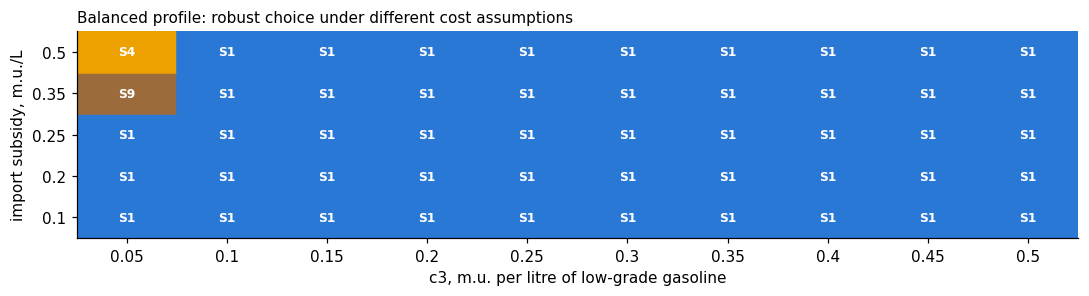

In [11]:
C3_GRID = np.round(np.linspace(C3_RANGE[0], C3_RANGE[1], 10), 3)
SUB_GRID = [0.1, 0.2, SUB0, 0.35, 0.5]

rows = []
for c3 in C3_GRID:
    norm = build_norm(c3=c3)
    for pname, w in PROFILES.items():
        best, rob, _ = choose(evaluate(w, norm), "p90")
        rows.append({"c3": c3, "profile": pname, "robust": rob, **{f"best@{sh}": best[sh] for sh in SHOCKS}})
C3S = pd.DataFrame(rows)
C3S.to_csv(OUT_DIR / "stage4_c3_sensitivity.csv", index=False, encoding="utf-8-sig")
print("Robust choice by profile (rows) and c3 (columns), nominal subsidy:")
display(C3S.pivot(index="profile", columns="c3", values="robust"))

grid_cs = []
for sub in SUB_GRID:
    for c3 in C3_GRID:
        best, rob, _ = choose(evaluate(PROFILES["balanced"], build_norm(c3=c3, subsidy=sub)), "p90")
        grid_cs.append({"subsidy": sub, "c3": c3, "robust": rob})
GCS = pd.DataFrame(grid_cs)
GCS.to_csv(OUT_DIR / "stage4_c3_subsidy_balanced.csv", index=False, encoding="utf-8-sig")
M = GCS.pivot(index="subsidy", columns="c3", values="robust")
fig, ax = plt.subplots(figsize=(10, 2.8))
for i, sub in enumerate(M.index):
    for j, c3 in enumerate(M.columns):
        s = M.loc[sub, c3]
        ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, color=SCOL[s]))
        ax.text(j, i, s, ha="center", va="center", fontsize=8, color="white", fontweight="bold")
ax.set_xlim(-0.5, len(M.columns) - 0.5); ax.set_ylim(-0.5, len(M.index) - 0.5)
ax.set_xticks(range(len(M.columns)), M.columns); ax.set_yticks(range(len(M.index)), M.index); ax.grid(False)
ax.set_xlabel("c3, m.u. per litre of low-grade gasoline"); ax.set_ylabel("import subsidy, m.u./L")
ax.set_title("Balanced profile: robust choice under different cost assumptions", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

For the balanced profile, the robust choice remains S1 in 48 of 50 combinations of c3 and import subsidy. It changes only when low-grade gasoline is assumed almost harmless (c3 = 0.05) and imports are expensive (subsidy ≥ 0.35): then strategies relying less on imports and more on low-grade gasoline become preferable

## 4.6. Stage summary

In [12]:
c3_stable = {p: C3S[C3S.profile == p].robust.nunique() == 1 for p in PROFILES}
SUMMARY = {
    "created": time.strftime("%Y-%m-%d %H:%M"), "model_sha256": PREP["model_sha256"],
    "profiles": PROFILES, "selection": "P90 of weighted score over 80 scenarios per shock",
    "priority_table": PRIO[[f"best@{sh}" for sh in SHOCKS] + ["robust_all_shocks", "robust_runner_up"]].to_dict(orient="index"),
    "weight_map_robust_share": WMAP.robust.value_counts(normalize=True).round(3).to_dict(),
    "robust_choice_stable_over_c3": c3_stable,
    "pareto_nondominated_mean": {str(sh): PARETO[(PARETO.shock == sh) & PARETO.nd_mean].strategy.tolist() for sh in SHOCKS},
}
(OUT_DIR / "stage4_summary.json").write_text(json.dumps(SUMMARY, indent=1, ensure_ascii=False, default=float), encoding="utf-8")
print(json.dumps({k: SUMMARY[k] for k in ["priority_table", "weight_map_robust_share", "robust_choice_stable_over_c3",
                                          "pareto_nondominated_mean"]}, indent=1, default=float))

{
 "priority_table": {
  "balanced": {
   "best@0.2": "S1",
   "best@0.45": "S1",
   "best@0.7": "S1",
   "robust_all_shocks": "S1",
   "robust_runner_up": "S8"
  },
  "shortage_first": {
   "best@0.2": "S8",
   "best@0.45": "S1",
   "best@0.7": "S1",
   "robust_all_shocks": "S1",
   "robust_runner_up": "S8"
  },
  "price_first": {
   "best@0.2": "S2",
   "best@0.45": "S8",
   "best@0.7": "S8",
   "robust_all_shocks": "S8",
   "robust_runner_up": "S1"
  },
  "budget_first": {
   "best@0.2": "S1",
   "best@0.45": "S1",
   "best@0.7": "S9",
   "robust_all_shocks": "S9",
   "robust_runner_up": "S1"
  },
  "queues_first": {
   "best@0.2": "S8",
   "best@0.45": "S1",
   "best@0.7": "S1",
   "robust_all_shocks": "S1",
   "robust_runner_up": "S9"
  },
  "physical_security": {
   "best@0.2": "S8",
   "best@0.45": "S1",
   "best@0.7": "S1",
   "robust_all_shocks": "S1",
   "robust_runner_up": "S9"
  }
 },
 "weight_map_robust_share": {
  "S1": 0.403,
  "S8": 0.242,
  "S7": 0.199,
  "S2": 0.121,
